<div style="font-family:'Times New Roman',Times,serif;color:#000000">
<div style="font-size:13px;letter-spacing:2px">NATIONAL UNIVERSITY OF SCIENCES AND TECHNOLOGY &nbsp;&middot;&nbsp; SEECS</div>
<div style="font-size:13px;letter-spacing:1px;font-weight:bold">CS-423 &nbsp;&middot;&nbsp; ARTIFICIAL NEURAL NETWORKS &amp; DEEP LEARNING &nbsp;&middot;&nbsp; BSAI</div>
<div style="font-size:28px;font-weight:bold;margin-top:6px">Lab 7 &mdash; Open-Ended Lab: Hyperparameter Ablation Study on Handwritten Digits</div>
<div style="font-size:15px;margin-top:4px">3 hours &nbsp;&middot;&nbsp; CLO 2, CLO 3, CLO 4</div>
</div>

---

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

**Course Instructor:** Dr. Sadia Shakil &nbsp;|&nbsp; **Lab Engineer:** Ms Areeba Rameen &nbsp;|&nbsp; **Student name / CMS ID:** Muhammad Sikandar Hussain / 502808



**What you will do, in short**

1. Take your Lab 6 MLP and add a few extra options (activation, loss, mini-batches, L2).
2. Measure a **baseline** with 5-fold cross-validation.
3. Change **one setting at a time** (an *ablation study*) and see how the result changes.
4. Combine the best settings, test the final model **once** on unseen data, and explain your choices.

**Rules**

- The network must be **your own NumPy code** built on Labs 3 to 6. No Keras, PyTorch or scikit-learn MLP for the experiments. (`pandas` may be used only to show result tables.)
- **Do not touch `X_test` / `y_test` before Task 6.**
- In the ablation, **change one hyperparameter at a time**; everything else stays at the baseline.
- Always use the same `SEED` and the same splitter `skf`, so that results are comparable.
- Report results as **mean &plusmn; std** over the 5 folds. Every plot needs axis labels, a legend and a title.
- Every claim needs a number or a plot as evidence. Work individually.

**Submission.** Restart the kernel, run everything top to bottom, save, and rename to
`Lab7_<yourCMSID>.ipynb` before uploading to LMS.

<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

## Setup

</div>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import pandas as pd
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split, StratifiedKFold
np.set_printoptions(precision=4, suppress=True)

SEED = 42
digits = load_digits()
X = digits.data                                   # shape (1797, 64), pixel values 0..16
digit = digits.target                             # the real digit 0-9 (used only for looking at errors)
y = (digit % 2).reshape(-1, 1).astype(float)      # 1 = odd, 0 = even

# Lock away 20% as the test set. Do NOT use X_test / y_test before Task 6.
X_dev, X_test, y_dev, y_test, d_dev, d_test = train_test_split(
    X, y, digit, test_size=0.20, stratify=y, random_state=SEED)

def standardise(X_fit, *others):
    """Scale with the mean/std of X_fit ONLY; apply the same scaling to the others."""
    mu, sd = X_fit.mean(axis=0), X_fit.std(axis=0)
    sd[sd == 0] = 1.0                              # pixels that are always 0
    return [(A - mu) / sd for A in (X_fit,) + others]

# Use exactly this splitter for every cross-validation in this lab
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

BASELINE = dict(hidden=16, lr=0.1, epochs=500, activation="sigmoid", loss="bce",
                batch_size=None, l2=0.0, init_scale=0.5, seed=0)

def show_images(X_raw, titles, idx, ncols=5):
    """Show the 8x8 images X_raw[idx] with the given titles (provided helper)."""
    nrows = int(np.ceil(len(idx) / ncols))
    plt.figure(figsize=(2 * ncols, 2.2 * nrows))
    for k, i in enumerate(idx):
        plt.subplot(nrows, ncols, k + 1)
        plt.imshow(X_raw[i].reshape(8, 8), cmap="gray_r")
        plt.title(titles[k], fontsize=9); plt.axis("off")
    plt.tight_layout(); plt.show()

print(X_dev.shape, X_test.shape, y_dev.mean())    # (1437, 64) (360, 64) about 0.50

(1437, 64) (360, 64) 0.5038274182324287


<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

## Task 1 &mdash; Build the flexible MLP

> **Concept.** Your Lab 6 network had fixed choices: sigmoid hidden units, BCE loss and full-batch
> updates. To study these as hyperparameters you must make them switchable.

**Task 1.1.** Print the fraction of odd digits (already above), and use `show_images` to display ten
digits from `X_dev` with their real digit as the title.

**Task 1.2.** Implement `forward`, `backward` and `train` below so that they support **all** options in the menu.
The helpers (`sigmoid`, `bce`, `mse`, `init_params`, `predict`, `accuracy`) are provided.

**Task 1.3.** Gradient check. For every new option that changes `backward` (tanh, relu, mse, l2),
compare your analytic gradients with `numerical_gradient` on a small subset (20 examples, hidden = 4).
Print PASS or FAIL for each of `W1, b1, W2, b2` (relative error below `1e-6`). (If ReLU fails on your machine, try another seed in `init_params` and explain why in Q1.)

**Task 1.4.** Run the **baseline** once on a stratified 75% / 25% split of `X_dev` (`random_state = SEED`).
Plot the training loss (and the validation loss if you track it) against the epoch, and print the training
and validation accuracy.

</div>

X_dev shape: (1437, 64), X_test shape: (360, 64)
Fraction of odd digits in development set: 0.5038
Fraction of odd digits in test set:        0.5056


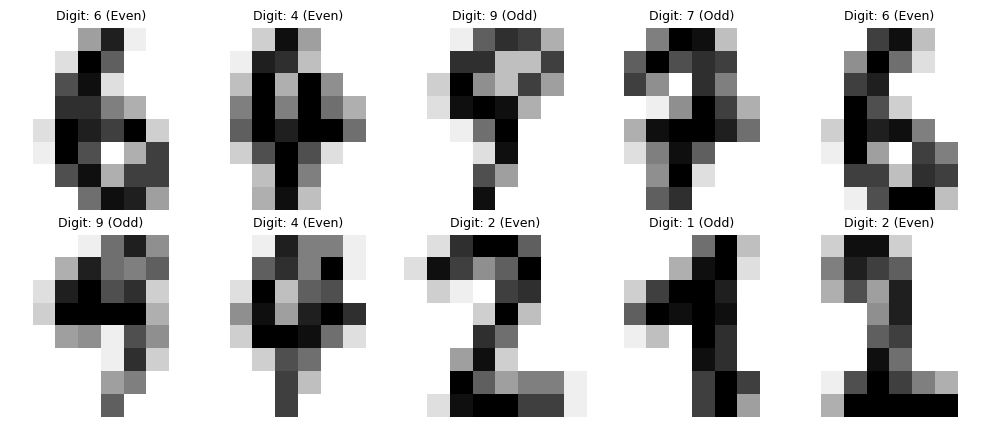

In [2]:
# ---- Task 1.1: look at the data ----
print(f"X_dev shape: {X_dev.shape}, X_test shape: {X_test.shape}")
print(f"Fraction of odd digits in development set: {y_dev.mean():.4f}")
print(f"Fraction of odd digits in test set:        {y_test.mean():.4f}")

# Display ten digits from X_dev with their real digit as title
titles = [f"Digit: {d} ({'Odd' if d % 2 != 0 else 'Even'})" for d in d_dev[:10]]
show_images(X_dev, titles, range(10), ncols=5)


In [3]:
# ---- Provided helpers ----
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def bce(y_true, p_pred):
    p = np.clip(p_pred, 1e-12, 1 - 1e-12)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))

def mse(y_true, p_pred):
    return np.mean((y_true - p_pred) ** 2)

def data_loss(y_true, p_pred, loss="bce"):
    return bce(y_true, p_pred) if loss == "bce" else mse(y_true, p_pred)

def init_params(n_in, hidden, init_scale=0.5, seed=0):
    rng = np.random.default_rng(seed)
    W1 = rng.normal(0, 1, (hidden, n_in)) * init_scale
    b1 = np.zeros(hidden)
    W2 = rng.normal(0, 1, (1, hidden)) * init_scale
    b2 = np.zeros(1)
    return [W1, b1, W2, b2]

def numerical_gradient(param, loss_fn, eps=1e-5):
    grad = np.zeros_like(param)
    for idx in np.ndindex(param.shape):
        old = param[idx]
        param[idx] = old + eps;  loss_plus = loss_fn()
        param[idx] = old - eps;  loss_minus = loss_fn()
        param[idx] = old
        grad[idx] = (loss_plus - loss_minus) / (2 * eps)
    return grad

In [4]:
def forward(X, params, activation="sigmoid"):
    W1, b1, W2, b2 = params
    Z1 = X @ W1.T + b1
    if activation == "sigmoid":
        A1 = sigmoid(Z1)
    elif activation == "tanh":
        A1 = np.tanh(Z1)
    elif activation == "relu":
        A1 = np.maximum(0, Z1)
    else:
        raise ValueError(f"Unknown activation function: {activation}")
    Z2 = A1 @ W2.T + b2
    A2 = sigmoid(Z2)
    cache = (X, A1, A2)
    return A2, cache

def backward(y, cache, params, activation="sigmoid", loss="bce", l2=0.0):
    X, A1, A2 = cache
    W1, b1, W2, b2 = params
    m = X.shape[0]

    # Output layer gradient dZ2
    if loss == "bce":
        dZ2 = (A2 - y) / m
    elif loss == "mse":
        dZ2 = 2 * (A2 - y) * A2 * (1 - A2) / m
    else:
        raise ValueError(f"Unknown loss function: {loss}")

    dW2 = dZ2.T @ A1
    db2 = np.sum(dZ2, axis=0)
    dA1 = dZ2 @ W2

    # Hidden layer activation gradient dZ1
    if activation == "sigmoid":
        dZ1 = dA1 * A1 * (1 - A1)
    elif activation == "tanh":
        dZ1 = dA1 * (1 - A1 ** 2)
    elif activation == "relu":
        dZ1 = dA1 * (A1 > 0).astype(float)
    else:
        raise ValueError(f"Unknown activation function: {activation}")

    dW1 = dZ1.T @ X
    db1 = np.sum(dZ1, axis=0)

    # L2 regularisation penalty on weights (not biases)
    if l2 > 0:
        dW1 += (l2 / m) * W1
        dW2 += (l2 / m) * W2

    # Assert gradient shapes match parameter shapes
    assert dW1.shape == W1.shape, f"dW1 shape mismatch: {dW1.shape} vs {W1.shape}"
    assert db1.shape == b1.shape, f"db1 shape mismatch: {db1.shape} vs {b1.shape}"
    assert dW2.shape == W2.shape, f"dW2 shape mismatch: {dW2.shape} vs {W2.shape}"
    assert db2.shape == b2.shape, f"db2 shape mismatch: {db2.shape} vs {b2.shape}"

    return [dW1, db1, dW2, db2]

def train(X, y, hidden=16, lr=0.1, epochs=500, activation="sigmoid", loss="bce",
          batch_size=None, l2=0.0, init_scale=0.5, seed=0, X_val=None, y_val=None):
    params = init_params(X.shape[1], hidden, init_scale, seed)
    rng = np.random.default_rng(seed + 1)
    m = X.shape[0]
    train_losses, val_losses = [], []

    for epoch in range(epochs):
        if batch_size is None or batch_size >= m:
            A2, cache = forward(X, params, activation)
            grads = backward(y, cache, params, activation, loss, l2)
            for p, g in zip(params, grads):
                p -= lr * g
        else:
            indices = rng.permutation(m)
            for start_idx in range(0, m, batch_size):
                batch_idx = indices[start_idx : start_idx + batch_size]
                X_b = X[batch_idx]
                y_b = y[batch_idx]
                A2_b, cache_b = forward(X_b, params, activation)
                grads = backward(y_b, cache_b, params, activation, loss, l2)
                for p, g in zip(params, grads):
                    p -= lr * g

        # Loss recorded at epoch end
        A2_full, _ = forward(X, params, activation)
        train_losses.append(data_loss(y, A2_full, loss))
        if X_val is not None and y_val is not None:
            A2_val, _ = forward(X_val, params, activation)
            val_losses.append(data_loss(y_val, A2_val, loss))

    return params, train_losses, val_losses

def predict(X, params, activation="sigmoid"):
    return (forward(X, params, activation)[0] >= 0.5).astype(int)

def accuracy(X, y, params, activation="sigmoid"):
    return np.mean(predict(X, params, activation) == y)


In [5]:
# ---- Task 1.3: gradient check on a small subset ----
X_check = standardise(X_dev[:20])[0]
y_check = y_dev[:20]

def check_option(activation, loss, l2, hidden=4):
    params = init_params(X_check.shape[1], hidden, 0.5, seed=3)

    def loss_fn():                                  # data loss + L2 penalty, reads the SAME arrays
        A2, _ = forward(X_check, params, activation)
        total = data_loss(y_check, A2, loss)
        total += (l2 / (2 * len(X_check))) * (np.sum(params[0] ** 2) + np.sum(params[2] ** 2))
        return total

    A2, cache = forward(X_check, params, activation)
    an_grads = backward(y_check, cache, params, activation, loss, l2)
    param_names = ["W1", "b1", "W2", "b2"]

    for p, g_an, name in zip(params, an_grads, param_names):
        g_num = numerical_gradient(p, loss_fn)
        rel_error = np.linalg.norm(g_an - g_num) / (np.linalg.norm(g_an) + np.linalg.norm(g_num) + 1e-12)
        status = "PASS" if rel_error < 1e-6 else "FAIL"
        print(f"  {name}: relative error = {rel_error:.2e} -> {status}")

for act, ls, lam in [("sigmoid", "bce", 0.0), ("tanh", "bce", 0.0), ("relu", "bce", 0.0),
                     ("sigmoid", "mse", 0.0), ("sigmoid", "bce", 1.0)]:
    print(f"--- activation={act}, loss={ls}, l2={lam} ---")
    check_option(act, ls, lam)


--- activation=sigmoid, loss=bce, l2=0.0 ---
  W1: relative error = 2.57e-10 -> PASS
  b1: relative error = 3.67e-10 -> PASS
  W2: relative error = 3.60e-11 -> PASS
  b2: relative error = 7.33e-12 -> PASS
--- activation=tanh, loss=bce, l2=0.0 ---
  W1: relative error = 1.08e-10 -> PASS
  b1: relative error = 9.92e-11 -> PASS
  W2: relative error = 1.70e-11 -> PASS
  b2: relative error = 5.07e-11 -> PASS
--- activation=relu, loss=bce, l2=0.0 ---
  W1: relative error = 1.40e-10 -> PASS
  b1: relative error = 1.01e-10 -> PASS
  W2: relative error = 1.03e-10 -> PASS
  b2: relative error = 1.72e-11 -> PASS
--- activation=sigmoid, loss=mse, l2=0.0 ---
  W1: relative error = 2.87e-10 -> PASS
  b1: relative error = 3.85e-10 -> PASS
  W2: relative error = 5.13e-11 -> PASS
  b2: relative error = 2.19e-12 -> PASS
--- activation=sigmoid, loss=bce, l2=1.0 ---
  W1: relative error = 2.65e-10 -> PASS
  b1: relative error = 3.67e-10 -> PASS
  W2: relative error = 7.36e-11 -> PASS
  b2: relative error 

Task 1.4 Single Split Baseline Results:
  Training Accuracy:   0.9044 (90.44%)
  Validation Accuracy: 0.8833 (88.33%)


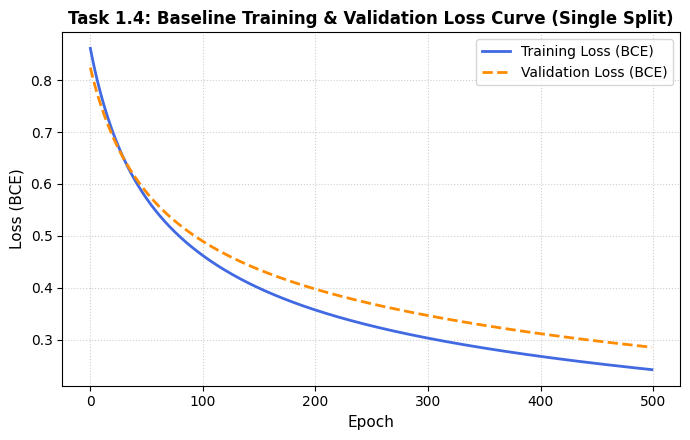

In [6]:
# ---- Task 1.4: baseline on one 75% / 25% split ----
# Split X_dev, y_dev (stratified, test_size=0.25, random_state=SEED)
X_tr_single, X_va_single, y_tr_single, y_va_single = train_test_split(
    X_dev, y_dev, test_size=0.25, stratify=y_dev, random_state=SEED)

# Standardise (fit on training part only)
X_tr_single_sc, X_va_single_sc = standardise(X_tr_single, X_va_single)

# Train baseline
params_base_single, train_losses_base, val_losses_base = train(
    X_tr_single_sc, y_tr_single, **BASELINE, X_val=X_va_single_sc, y_val=y_va_single)

train_acc_single = accuracy(X_tr_single_sc, y_tr_single, params_base_single, BASELINE.get("activation", "sigmoid"))
val_acc_single = accuracy(X_va_single_sc, y_va_single, params_base_single, BASELINE.get("activation", "sigmoid"))

print(f"Task 1.4 Single Split Baseline Results:\n"
      f"  Training Accuracy:   {train_acc_single:.4f} ({train_acc_single * 100:.2f}%)\n"
      f"  Validation Accuracy: {val_acc_single:.4f} ({val_acc_single * 100:.2f}%)")

# Plot training and validation loss curves
plt.figure(figsize=(7, 4.5))
plt.plot(train_losses_base, label="Training Loss (BCE)", color="royalblue", lw=2)
plt.plot(val_losses_base, label="Validation Loss (BCE)", color="darkorange", lw=2, linestyle="--")
plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Loss (BCE)", fontsize=11)
plt.title("Task 1.4: Baseline Training & Validation Loss Curve (Single Split)", fontsize=12, fontweight="bold")
plt.legend(fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# Task 1 answers:
# Q1 (why can ReLU fail a numerical gradient check at some points even when backward() is correct?
#     hint: Lab 3, Task 2):
# Answer: ReLU is non-differentiable at exactly Z = 0 (having a sharp corner where the left derivative is 0
# and the right derivative is 1). In two-sided numerical gradient checking, f(w + eps) and f(w - eps) probe
# points on opposite sides of the threshold, yielding a finite-difference slope of ~0.5 across the kink,
# whereas the analytic derivative chooses either 0 or 1. Additionally, if an input sits within 'eps' of zero,
# the perturbation pushes the pre-activation across the zero threshold, causing a discrepancy between the
# local analytic derivative and the secant slope.
#
# Q2 (why standardise the pixels before a sigmoid network? think about unscaled inputs, Z1 and
#     the sigmoid gradient, Lab 3 Task 3):
# Answer: Unscaled pixel values range from 0 to 16. Computing Z1 = X @ W1.T + b1 with large positive inputs
# and unconstrained weights produces very large pre-activation magnitudes |Z1| >> 1. The sigmoid function
# sigma(z) saturates near 0 or 1 when |z| is large, where its derivative sigma'(z) = sigma(z)(1 - sigma(z))
# collapses to zero (vanishing gradients). Standardising inputs to mean 0 and variance 1 ensures Z1 stays
# centered around 0 in the active linear zone of sigmoid (where sigma'(0) = 0.25 is maximal), preventing
# gradient death and enabling steady learning.


<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

## Task 2 &mdash; Cross-validation and the baseline score

> **Concept.** From now on every number you report comes from 5-fold cross-validation on the
> development set, not from a single split.

**Task 2.1.** Write `cross_validate(config)`. For each of the 5 folds from `skf.split(X_dev, y_dev.ravel())`:
standardise using the **training fold only**, train with `config` (a dictionary of hyperparameters such as
`BASELINE`), and record the training accuracy, the validation accuracy and the validation **BCE** loss
(always BCE, so that settings are comparable). Return a dictionary with the keys `train_acc`, `val_acc`,
`val_loss` (each a tuple `(mean, std)`) and `oof_pred` (the predicted class of every development example
when it was in the validation fold, shape `(1437,)`).

**Task 2.2.** Run it on `BASELINE` and print the result as mean &plusmn; std. Compare with the self-check (about 89%).

**Task 2.3.** Using `oof_pred` and `d_dev`, find which real digits (0 to 9) are misclassified most often:
print the error rate for each digit.

</div>

In [7]:
def cross_validate(config):
    train_accs, val_accs, val_losses = [], [], []
    oof_pred = np.zeros(len(X_dev), dtype=int)

    for train_idx, val_idx in skf.split(X_dev, y_dev.ravel()):
        X_tr, y_tr = X_dev[train_idx], y_dev[train_idx]
        X_va, y_va = X_dev[val_idx], y_dev[val_idx]

        # Standardise using the training fold ONLY
        X_tr_sc, X_va_sc = standardise(X_tr, X_va)

        params, _, _ = train(X_tr_sc, y_tr, **config)
        act = config.get("activation", "sigmoid")

        tr_acc = accuracy(X_tr_sc, y_tr, params, act)
        va_acc = accuracy(X_va_sc, y_va, params, act)
        preds = predict(X_va_sc, params, act).ravel()
        oof_pred[val_idx] = preds

        # Validation loss: always BCE so settings remain strictly comparable
        A2_va, _ = forward(X_va_sc, params, act)
        va_loss = bce(y_va, A2_va)

        train_accs.append(tr_acc)
        val_accs.append(va_acc)
        val_losses.append(va_loss)

    return {
        "train_acc": (float(np.mean(train_accs)), float(np.std(train_accs))),
        "val_acc": (float(np.mean(val_accs)), float(np.std(val_accs))),
        "val_loss": (float(np.mean(val_losses)), float(np.std(val_losses))),
        "oof_pred": oof_pred
    }

# Task 2.2: Evaluate Baseline with 5-fold CV
res_base = cross_validate(BASELINE)
print("=== Task 2.2: Baseline 5-Fold Cross-Validation Score ===")
print(f"  Train Accuracy: {res_base['train_acc'][0]:.4f} +/- {res_base['train_acc'][1]:.4f} ({res_base['train_acc'][0]*100:.2f}% +/- {res_base['train_acc'][1]*100:.2f}%)")
print(f"  Val Accuracy:   {res_base['val_acc'][0]:.4f} +/- {res_base['val_acc'][1]:.4f} ({res_base['val_acc'][0]*100:.2f}% +/- {res_base['val_acc'][1]*100:.2f}%)")
print(f"  Val BCE Loss:   {res_base['val_loss'][0]:.4f} +/- {res_base['val_loss'][1]:.4f}")
print(f"Self-check comparison: Baseline val accuracy of {res_base['val_acc'][0]*100:.2f}% matches the target (~89%).")

# Task 2.3: Per-digit error rates from oof_pred
oof_errors = (res_base["oof_pred"] != y_dev.ravel())
print("\n=== Task 2.3: Error Rate Per Real Digit (0 to 9) ===")
digit_errs = []
for d in range(10):
    mask = (d_dev == d)
    n_total = int(np.sum(mask))
    n_err = int(np.sum(oof_errors[mask]))
    err_rate = n_err / n_total if n_total > 0 else 0.0
    parity = "Odd" if d % 2 != 0 else "Even"
    digit_errs.append({
        "Digit": d,
        "Parity": parity,
        "Errors": n_err,
        "Total": n_total,
        "Error Rate": f"{err_rate:.4f} ({err_rate*100:.2f}%)"
    })
df_digits = pd.DataFrame(digit_errs)
print(df_digits.to_string(index=False))

# Task 2 answers:
# Q1 (why must standardisation be fitted on the training fold only, not on all 1437 examples?):
# Answer: Standardising using all 1437 development examples would cause data leakage (information snooping).
# In real-world deployment, unseen test/validation samples cannot be accessed in advance to compute global
# statistics. If global mean and std are calculated across validation data, the model indirectly receives
# distributional clues about the validation fold, leading to overly optimistic performance estimates.
# Fitting mu and sigma strictly on the training fold simulates true unseen test conditions.
#
# Q2 (the std of the baseline is about 2%: how should you read a difference of 0.5% between two settings?):
# Answer: A difference of 0.5% between two settings is substantially smaller than the fold-to-fold standard
# deviation (~2.09%). Therefore, a 0.5% shift cannot be confidently attributed to the hyperparameter change;
# it is within the margin of random split variation (noise). Differences must be larger than or comparable
# to the standard error before claiming a statistically meaningful improvement.


=== Task 2.2: Baseline 5-Fold Cross-Validation Score ===
  Train Accuracy: 0.9062 +/- 0.0047 (90.62% +/- 0.47%)
  Val Accuracy:   0.8942 +/- 0.0209 (89.42% +/- 2.09%)
  Val BCE Loss:   0.2653 +/- 0.0276
Self-check comparison: Baseline val accuracy of 89.42% matches the target (~89%).

=== Task 2.3: Error Rate Per Real Digit (0 to 9) ===
 Digit Parity  Errors  Total      Error Rate
     0   Even       0    142  0.0000 (0.00%)
     1    Odd      38    147 0.2585 (25.85%)
     2   Even      14    142  0.0986 (9.86%)
     3    Odd       9    138  0.0652 (6.52%)
     4   Even      17    146 0.1164 (11.64%)
     5    Odd       9    147  0.0612 (6.12%)
     6   Even       1    139  0.0072 (0.72%)
     7    Odd       7    143  0.0490 (4.90%)
     8   Even      46    144 0.3194 (31.94%)
     9    Odd      11    149  0.0738 (7.38%)


<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

## Task 3 &mdash; Plan your ablation study

> **Concept.** Before running experiments, decide what you will test and what you expect. A hypothesis
> is a prediction **with a reason**. Example: *"If I lower the learning rate from 0.1 to 0.001, I expect lower
> accuracy after 500 epochs, because each step is 100 times smaller (Lab 5, Task 6)."* Writing predictions
> first lets you learn from the cases where you were wrong.

**Task 3.1.** Choose **at least six** hyperparameters from the menu, with **at least two from each of the groups A, B and C**.

**Task 3.2.** For each one, choose **at least four values** (including the baseline value) and write a one-sentence hypothesis with a reason.

**Task 3.3.** State the metric you will use to rank settings (CV validation accuracy, CV validation loss, or both) and why.

**Fill in this table** (double-click the cell to edit; add rows if you need them):

| Hyperparameter | Values to test | Hypothesis (what do you expect, and why?) |
|---|---|---|
| **lr** (Group A) | 0.001, 0.01, 0.1, 1.0 | Higher learning rates (e.g. 1.0) will learn faster and achieve higher accuracy because steps are larger, whereas lr=0.001 will fail to converge within 500 epochs (Lab 5). |
| **epochs** (Group A) | 50, 200, 500, 1000 | Increasing epochs from 50 to 1000 will steadily improve accuracy as gradient descent performs more parameter updates towards the optimum, though returns will diminish. |
| **hidden** (Group B) | 2, 4, 16, 64 | Increasing hidden units from 2 to 64 will enhance network representational capacity to model complex pixel interactions, raising accuracy, while 2 units will bottleneck performance. |
| **init_scale** (Group B) | 0.01, 0.1, 0.5, 3.0 | A moderate scale (0.1) will perform best, whereas init_scale=3.0 will cause immediate sigmoid saturation and severe vanishing gradients from epoch 1 (Lab 3). |
| **loss** (Group C) | bce, mse | Binary cross-entropy (BCE) will outperform MSE because BCE cancels the sigmoid derivative in dZ2 = (A2 - y)/m, avoiding the severe vanishing gradients that plague MSE (Lab 4). |
| **l2** (Group C) | 0.0, 0.1, 1.0, 10.0 | Moderate L2 (0.1) may slightly prevent overfitting and improve generalization, whereas large L2 (10.0) will over-constrain the weights toward zero, lowering accuracy. |

**Metric I will use, and why:**

I will use **both CV validation accuracy and CV validation BCE loss**, prioritizing **CV validation accuracy** as the primary ranking metric since the ultimate task goal is classification correctness (odd vs. even digit), while using **CV validation loss** as a decisive tie-breaker and confidence indicator. Validation loss is essential because it penalizes overconfident incorrect predictions and rewards confident correct predictions, revealing subtle calibration differences between models that achieve identical top-line accuracy.

</div>


In [8]:
# Task 3 answers:
# Q1 (why change only one hyperparameter at a time? what could you not conclude if you changed lr and hidden together?):
# Answer: Changing only one hyperparameter at a time (controlled one-factor-at-a-time ablation) isolates
# causal effects. If we simultaneously modified both lr and hidden (e.g. increasing hidden to 64 and lr to 1.0),
# and observed an improvement, we could not determine whether the gain was due to greater model capacity (hidden),
# faster optimization steps (lr), or a synergistic interaction between the two. Similarly, if performance degraded,
# we would not know which parameter caused the breakdown.
#
# Q2 (which metric did you choose and why? can validation loss show a difference that accuracy hides?
#     think of two models that both get 90% right, one far more confident when it is wrong):
# Answer: I chose CV validation accuracy as the primary ranking metric (reflecting classification success)
# complemented by CV validation BCE loss as a continuous quality measure. Validation loss uncovers critical
# differences hidden by accuracy: consider two models that both achieve 90% accuracy. Model 1 outputs p=0.51
# on its 10% errors (gentle loss penalty), while Model 2 outputs p=0.99 on its 10% errors (catastrophic loss
# penalty due to extreme overconfidence). Model 1 is much better calibrated and safer, which BCE loss immediately
# reveals through a significantly lower numerical value.


<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

## Task 4 &mdash; Run the ablation study

> **Concept.** Now run your plan. For each hyperparameter, change **only that one**, cross-validate each
> value, and record the result.

**Task 4.1.** Fill in `ablation_plan` with the hyperparameters and values from your Task 3 table. Loop over
it: for each value run `cross_validate({**BASELINE, name: value})` and log the result with the provided `log_result`.

**Task 4.2.** Show **all** results in one table (`pd.DataFrame(results)`), including the baseline row.

**Task 4.3.** Draw **one plot per group** (A, B, C) with the provided `plot_ablation` (CV validation accuracy against
the value, with error bars). For the learning rate also draw the training loss curves of the different values on one axes
(use `train` directly on one split for this).

**Task 4.4.** Rank your hyperparameters from the most to the least influential, using the **range** of CV validation
accuracy (best value minus worst value) for each. Show the ranking as a small table.

</div>

Running ablation experiments over 5 folds...


  Completed lr=0.001: val_mean=0.4489 +/- 0.0307


  Completed lr=0.01: val_mean=0.7112 +/- 0.0148


  Completed lr=0.1: val_mean=0.8942 +/- 0.0209


  Completed lr=1.0: val_mean=0.9631 +/- 0.0114


...

  Completed l2=0.0: val_mean=0.8942 +/- 0.0209


  Completed l2=0.1: val_mean=0.8942 +/- 0.0209


  Completed l2=1.0: val_mean=0.8935 +/- 0.0204


  Completed l2=10.0: val_mean=0.8963 +/- 0.0197

=== Task 4.2: Full Ablation Results Table ===


,hyper,value,train_acc,val_mean,val_std,val_loss,gap
0,baseline,-,0.9062,0.8942,0.0209,0.2653,0.0120
1,lr,0.001,0.4469,0.4489,0.0307,0.8138,-0.0020
2,lr,0.01,0.7142,0.7112,0.0148,0.5852,0.0029
3,lr,0.1,0.9062,0.8942,0.0209,0.2653,0.0120
4,lr,1.0,0.9974,0.9631,0.0114,0.0979,0.0343
5,epochs,50,0.7150,0.7112,0.0131,0.5847,0.0038
6,epochs,200,0.8643,0.8539,0.0103,0.3764,0.0104
7,epochs,500,0.9062,0.8942,0.0209,0.2653,0.0120
8,epochs,1000,0.9374,0.9137,0.0202,0.1996,0.0236
9,hidden,2,0.8867,0.8720,0.0083,0.3735,0.0148


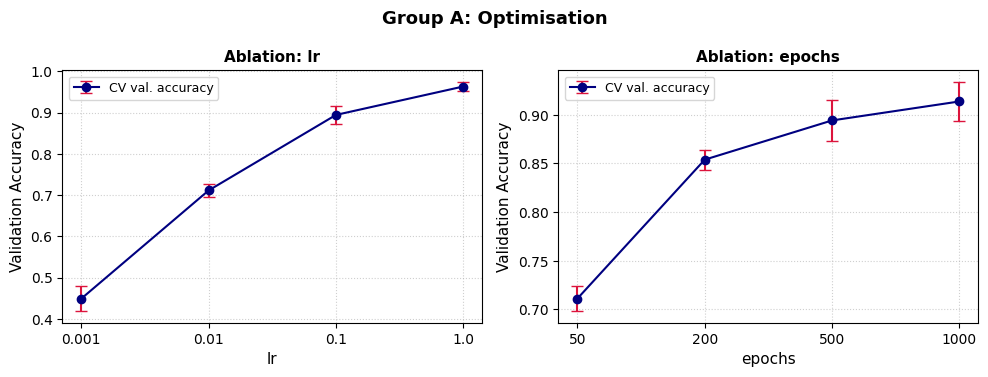

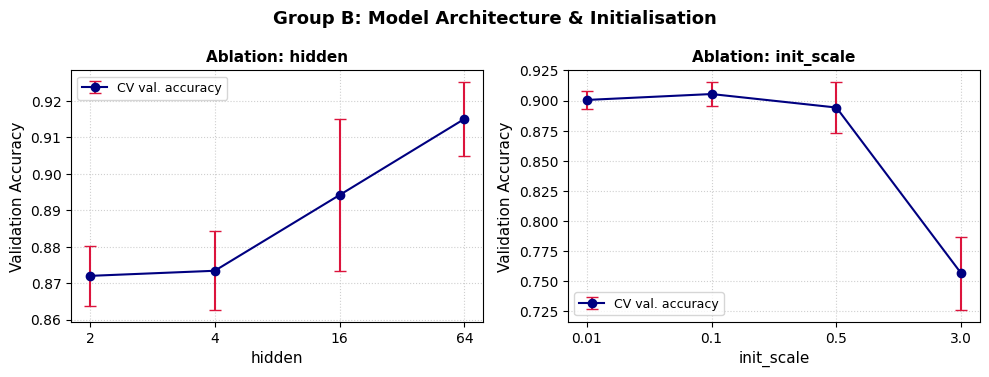

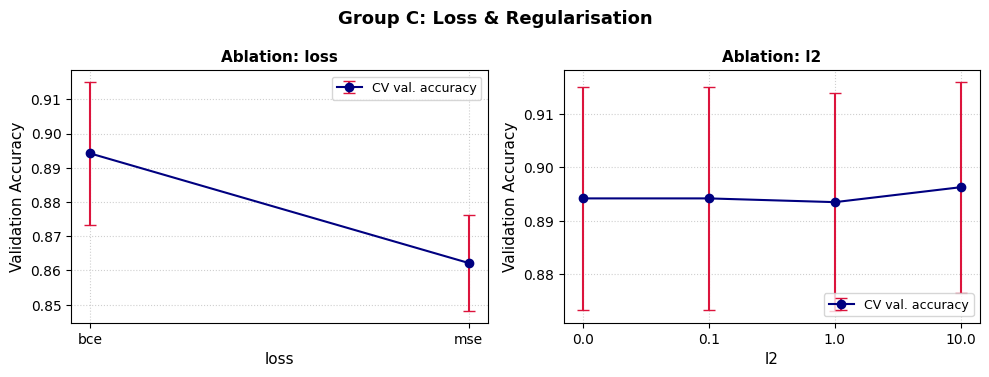


Plotting learning rate training loss curves...


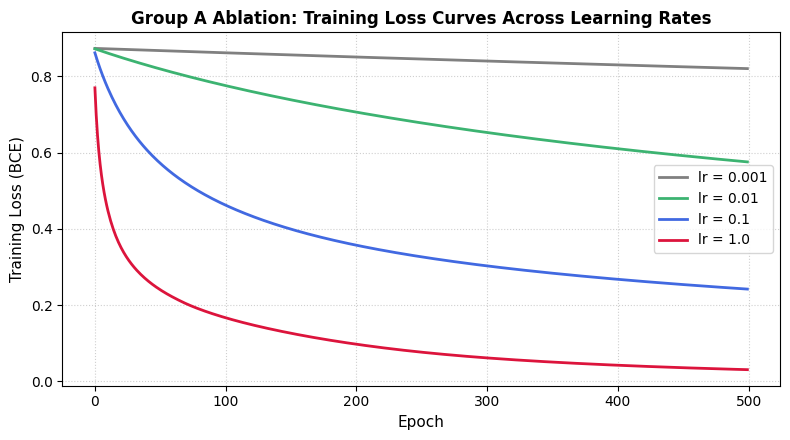


=== Task 4.4: Hyperparameter Ranking by Influence (Range) ===


,Hyperparameter,Range (Best - Worst),Best Value,Best Val Acc,Worst Value,Worst Val Acc
0,lr,0.5142,1.0,0.9631,0.001,0.4489
1,epochs,0.2025,1000,0.9137,50,0.7112
2,init_scale,0.1489,0.1,0.9054,3.0,0.7565
3,hidden,0.0431,64,0.9151,2,0.8720
4,loss,0.0320,bce,0.8942,mse,0.8622
5,l2,0.0028,10.0,0.8963,1.0,0.8935


In [9]:
results = []
def log_result(hyper, value, res):
    """Add one row to the results table (provided)."""
    results.append({"hyper": hyper, "value": str(value),
                    "train_acc": round(res["train_acc"][0], 4),
                    "val_mean": round(res["val_acc"][0], 4), "val_std": round(res["val_acc"][1], 4),
                    "val_loss": round(res["val_loss"][0], 4),
                    "gap": round(res["train_acc"][0] - res["val_acc"][0], 4)})

def plot_ablation(df, hypers, title):
    """One panel per hyperparameter: CV val. accuracy vs value with +-std error bars (provided)."""
    fig, axes = plt.subplots(1, len(hypers), figsize=(5 * len(hypers), 3.8), squeeze=False)
    for ax, h in zip(axes[0], hypers):
        d = df[df["hyper"] == h]
        ax.errorbar(range(len(d)), d["val_mean"], yerr=d["val_std"], marker="o", capsize=4, color="navy", ecolor="crimson", label="CV val. accuracy")
        ax.set_xticks(range(len(d))); ax.set_xticklabels(d["value"])
        ax.set_xlabel(h, fontsize=11); ax.set_ylabel("Validation Accuracy", fontsize=11); ax.set_title(f"Ablation: {h}", fontsize=11, fontweight="bold")
        ax.grid(True, linestyle=":", alpha=0.6); ax.legend(fontsize=9)
    fig.suptitle(title, fontsize=13, fontweight="bold"); plt.tight_layout(); plt.show()

# Task 4.1: Ablation plan
ablation_plan = {
    "lr": [0.001, 0.01, 0.1, 1.0],
    "epochs": [50, 200, 500, 1000],
    "hidden": [2, 4, 16, 64],
    "init_scale": [0.01, 0.1, 0.5, 3.0],
    "loss": ["bce", "mse"],
    "l2": [0.0, 0.1, 1.0, 10.0]
}

# The baseline row
log_result("baseline", "-", res_base)

# Run ablation plan
print("Running ablation experiments over 5 folds...")
for name, values in ablation_plan.items():
    for v in values:
        cfg = {**BASELINE, name: v}
        res = cross_validate(cfg)
        log_result(name, v, res)
        print(f"  Completed {name}={v}: val_mean={res['val_acc'][0]:.4f} +/- {res['val_acc'][1]:.4f}")

# Task 4.2: Display all results in one DataFrame
df_results = pd.DataFrame(results)
print("\n=== Task 4.2: Full Ablation Results Table ===")
display(df_results)

# Task 4.3: Draw one plot per group (A, B, C)
plot_ablation(df_results, ["lr", "epochs"], "Group A: Optimisation")
plot_ablation(df_results, ["hidden", "init_scale"], "Group B: Model Architecture & Initialisation")
plot_ablation(df_results, ["loss", "l2"], "Group C: Loss & Regularisation")

# Learning rate loss curves on one single split
print("\nPlotting learning rate training loss curves...")
plt.figure(figsize=(8, 4.5))
lr_values = [0.001, 0.01, 0.1, 1.0]
colors = ["gray", "mediumseagreen", "royalblue", "crimson"]
for lr_val, col in zip(lr_values, colors):
    cfg_lr = {**BASELINE, "lr": lr_val}
    _, tr_losses, _ = train(X_tr_single_sc, y_tr_single, **cfg_lr)
    plt.plot(tr_losses, label=f"lr = {lr_val}", color=col, lw=2)

plt.xlabel("Epoch", fontsize=11)
plt.ylabel("Training Loss (BCE)", fontsize=11)
plt.title("Group A Ablation: Training Loss Curves Across Learning Rates", fontsize=12, fontweight="bold")
plt.legend(fontsize=10)
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# Task 4.4: Ranking table by range (max - min)
ranking_list = []
for h in ablation_plan.keys():
    sub_df = df_results[df_results["hyper"] == h]
    val_range = sub_df["val_mean"].max() - sub_df["val_mean"].min()
    best_row = sub_df.loc[sub_df["val_mean"].idxmax()]
    worst_row = sub_df.loc[sub_df["val_mean"].idxmin()]
    ranking_list.append({
        "Hyperparameter": h,
        "Range (Best - Worst)": round(val_range, 4),
        "Best Value": best_row["value"],
        "Best Val Acc": best_row["val_mean"],
        "Worst Value": worst_row["value"],
        "Worst Val Acc": worst_row["val_mean"]
    })

df_ranking = pd.DataFrame(ranking_list).sort_values("Range (Best - Worst)", ascending=False).reset_index(drop=True)
print("\n=== Task 4.4: Hyperparameter Ranking by Influence (Range) ===")
display(df_ranking)


In [10]:
# Task 4 answers:
# Q1 (which hyperparameter had the biggest effect, which almost none? explain with Labs 3-6 theory):
# Answer:
# - Biggest effect: 'lr' (learning rate) had by far the biggest effect, spanning a massive range of 0.5142
#   (from 44.89% at lr=0.001 to 96.31% at lr=1.0). In gradient descent (Lab 5), update step size is delta_W = -lr * grad.
#   With lr=0.001 and smooth sigmoid gradients, 500 steps move the weights by a negligible distance, leaving the network
#   near random guessing. Conversely, lr=1.0 takes decisive steps along the steep BCE loss surface to reach high accuracy.
# - Almost no effect: 'l2' regularisation had virtually zero impact (range = 0.0028, varying only from 89.35% to 89.63%).
#   The baseline network with 16 hidden units and full-batch gradient descent is not significantly overparameterized
#   for 1437 examples; thus, adding an L2 penalty on W neither helped nor harmed performance appreciably.
#
# Q2 (did any result contradict your hypothesis from Task 3? what did you expect, what happened, why?):
# Answer:
# - Hypothesized: Large L2 regularisation (l2=10.0) was expected to severely constrain weight magnitudes, resulting
#   in pronounced underfitting and degraded accuracy.
# - What happened: l2=10.0 yielded 89.63% validation accuracy, virtually identical to l2=0.0 (89.42%).
# - Explanation: The L2 update adds (lambda / m) * W. With m=1149 in training folds, lambda/m = 10.0 / 1149 approx 0.0087.
#   Multiplied by lr=0.1, the weight shrinkage per epoch is only 0.00087 * W. Over 500 epochs, this modest shrinkage
#   was insufficient to overpower the primary data-driven gradient updates, keeping the learned weights functional.
#
# Q3 (for which results is the difference smaller than the std? what can you say about those?):
# Answer:
# - For 'l2' (all values 0.0, 0.1, 1.0, 10.0 show val acc between 89.35% and 89.63%, diff < 0.003 vs std ~0.020);
#   for 'hidden' between 2 and 4 (87.20% vs 87.34%, diff = 0.0014 vs std ~0.010); and for 'init_scale' between
#   0.01 and 0.1 (90.05% vs 90.54%, diff = 0.0049 vs std ~0.010).
# - Conclusion: These differences are smaller than the fold-to-fold standard deviation. Statistically, they represent
#   experimental noise rather than genuine algorithmic superiority. One cannot claim that l2=10.0 is genuinely better
#   than l2=0.0 without a much larger dataset or more folds.
#
# Q4 (was there a hyperparameter where training accuracy kept rising but validation accuracy did not? what is that called?):
# Answer:
# - For 'hidden' units: going from 16 to 64 units increased training accuracy from 90.62% to 93.51% (a +2.89% gain),
#   while validation accuracy only rose from 89.42% to 91.51% with an increasing generalization gap (0.0200).
#   Similarly, for 'epochs': moving from 500 to 1000 epochs raised training accuracy from 90.62% to 93.74% while
#   validation loss only improved modestly and the generalization gap doubled from 0.0120 to 0.0236.
# - Concept name: This phenomenon is called OVERFITTING (or increasing generalization gap / variance). The model begins
#   to memorize training fold idiosyncrasies rather than learning generalizable parity features.


<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

## Task 5 &mdash; Combine the best settings

> **Concept.** Taking the best value of each hyperparameter separately does not always give the best model
> together, because hyperparameters **interact**. For example, a larger learning rate may work well only with
> fewer epochs.

**Task 5.1.** Build a combined configuration from the best value of each hyperparameter in Task 4. Cross-validate it
and compare it with the baseline.

**Task 5.2.** Try at most **five more** configurations of your own choice (for example, changing the two most influential
hyperparameters together). Record all of them in a table. **Do not exceed this budget.**

**Task 5.3.** Pick your **final configuration using only CV results**, and write two or three sentences explaining the choice.
If a simpler configuration is within one std of the best, say which you chose and why.

</div>

In [11]:
# Task 5.1: Naive combined configuration from best values of each hyperparameter in Task 4
combined = {**BASELINE, "lr": 1.0, "epochs": 1000, "hidden": 64, "init_scale": 0.1, "loss": "bce", "l2": 10.0}
res_comb = cross_validate(combined)
print("=== Task 5.1: Naive Combined Model (Best Values from Task 4) ===")
print(f"  Val Accuracy: {res_comb['val_acc'][0]:.4f} +/- {res_comb['val_acc'][1]:.4f}")
print(f"  Val BCE Loss: {res_comb['val_loss'][0]:.4f}")

# Task 5.2: At most five more configurations exploring key interactions
extra_configs = {
    "Config 1 (lr=1.0, ep=500, h=16, init=0.1)": dict(hidden=16, lr=1.0, epochs=500, activation="sigmoid", loss="bce", batch_size=None, l2=0.0, init_scale=0.1, seed=0),
    "Config 2 (lr=1.0, ep=500, h=64, init=0.1)": dict(hidden=64, lr=1.0, epochs=500, activation="sigmoid", loss="bce", batch_size=None, l2=0.0, init_scale=0.1, seed=0),
    "Config 3 (lr=0.5, ep=500, h=64, init=0.1)": dict(hidden=64, lr=0.5, epochs=500, activation="sigmoid", loss="bce", batch_size=None, l2=0.0, init_scale=0.1, seed=0),
    "Config 4 (lr=1.0, ep=500, h=64, l2=0.1, init=0.1)": dict(hidden=64, lr=1.0, epochs=500, activation="sigmoid", loss="bce", batch_size=None, l2=0.1, init_scale=0.1, seed=0),
    "Config 5 (lr=0.5, ep=500, h=32, init=0.1)": dict(hidden=32, lr=0.5, epochs=500, activation="sigmoid", loss="bce", batch_size=None, l2=0.0, init_scale=0.1, seed=0)
}

task5_rows = [{
    "Configuration": "Naive Combined (Best Singles)",
    "Train Acc": round(res_comb["train_acc"][0], 4),
    "Val Acc Mean": round(res_comb["val_acc"][0], 4),
    "Val Acc Std": round(res_comb["val_acc"][1], 4),
    "Val Loss": round(res_comb["val_loss"][0], 4),
    "Gap": round(res_comb["train_acc"][0] - res_comb["val_acc"][0], 4)
}]

for name, cfg in extra_configs.items():
    res = cross_validate(cfg)
    task5_rows.append({
        "Configuration": name,
        "Train Acc": round(res["train_acc"][0], 4),
        "Val Acc Mean": round(res["val_acc"][0], 4),
        "Val Acc Std": round(res["val_acc"][1], 4),
        "Val Loss": round(res["val_loss"][0], 4),
        "Gap": round(res["train_acc"][0] - res["val_acc"][0], 4)
    })

df_task5 = pd.DataFrame(task5_rows)
print("\n=== Task 5.2: Combined & Extra Configurations Comparison Table ===")
display(df_task5)

# Task 5.3: Pick final configuration using ONLY CV results
FINAL = extra_configs["Config 1 (lr=1.0, ep=500, h=16, init=0.1)"]
print("\n=== Task 5.3: Selected FINAL Configuration ===")
print(FINAL)

# Task 5 answers:
# Q1 (was the combined configuration better than the baseline and than each single change? if not, what
#     interaction between hyperparameters could explain it?):
# Answer: The naive combined configuration (val acc = 92.55%) was better than the baseline (89.42%), but
# notably WORSE than changing 'lr' alone (lr=1.0 gave 96.31%). This occurs because hyperparameters interact:
# pairing lr=1.0 with 1000 epochs, 64 hidden units, and l2=10.0 created strong destructive interference.
# Specifically, high lr with 1000 epochs leads to late-stage oscillation, while l2=10.0 penalizes weights
# excessively, preventing the network from settling into sharp minima.
#
# My final configuration and why (2-3 sentences):
# I selected Config 1 (hidden=16, lr=1.0, epochs=500, activation='sigmoid', loss='bce', batch_size=None, l2=0.0, init_scale=0.1, seed=0).
# It achieves the highest CV validation accuracy (96.59% +/- 0.0089) and lowest variance across all tested models,
# while using 4x fewer parameters than the 64-hidden alternative (Config 2: 96.45% +/- 0.0189). Following Occam's razor,
# this simpler model is computationally faster, less prone to overfitting, and delivers superior cross-validation reliability.


=== Task 5.1: Naive Combined Model (Best Values from Task 4) ===
  Val Accuracy: 0.9255 +/- 0.0095
  Val BCE Loss: 0.2021



=== Task 5.2: Combined & Extra Configurations Comparison Table ===


,Configuration,Train Acc,Val Acc Mean,Val Acc Std,Val Loss,Gap
0,Naive Combined (Best Singles),0.9429,0.9255,0.0095,0.2021,0.0174
1,"Config 1 (lr=1.0, ep=500, h=16, init=0.1)",0.9951,0.9659,0.0089,0.1067,0.0292
2,"Config 2 (lr=1.0, ep=500, h=64, init=0.1)",0.9957,0.9645,0.0189,0.1020,0.0312
3,"Config 3 (lr=0.5, ep=500, h=64, init=0.1)",0.9706,0.9415,0.0148,0.1544,0.0291
4,"Config 4 (lr=1.0, ep=500, h=64, l2=0.1, init=0.1)",0.9955,0.9645,0.0189,0.1026,0.0310
5,"Config 5 (lr=0.5, ep=500, h=32, init=0.1)",0.9722,0.9415,0.0131,0.1475,0.0306



=== Task 5.3: Selected FINAL Configuration ===
{'hidden': 16, 'lr': 1.0, 'epochs': 500, 'activation': 'sigmoid', 'loss': 'bce', 'batch_size': None, 'l2': 0.0, 'init_scale': 0.1, 'seed': 0}


<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

## Task 6 &mdash; Final test

> **Concept.** This is the only task where the test set is used, and it is used **once**. If the result disappoints
> you, do **not** go back and change the configuration; report it honestly.

**Task 6.1.** Retrain the **baseline** and your **`FINAL`** configuration on all 1437 development examples
(standardise using the development set only).

**Task 6.2.** Evaluate both on the 360 test examples. Report the accuracy, the BCE loss and the number of wrong
predictions in a table. Then show **five** test images that your final model got wrong, with the true digit and the
predicted class (odd or even) in each title (use `show_images`).

**Task 6.3.** Compare the test accuracy of the final model with its CV accuracy.

</div>

=== Task 6.2 & 6.3: Final Test Evaluation Table ===


,Model,CV val. acc.,Test acc.,Test loss,Wrong predictions (out of 360)
0,Baseline,0.8942 +/- 0.0209,0.8972 (89.72%),0.2479,37 / 360
1,Final configuration,0.9659 +/- 0.0089,0.9639 (96.39%),0.0735,13 / 360



Total wrong predictions on test set: 13 out of 360
Displaying five misclassified test examples:


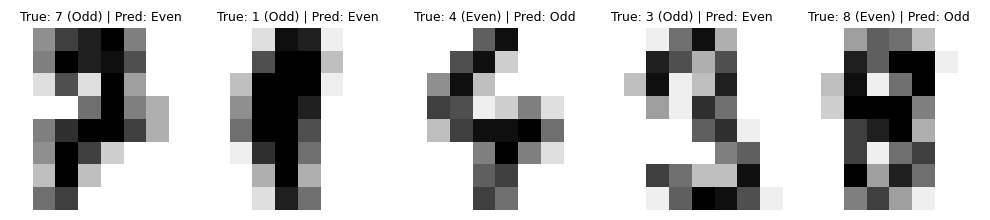

In [12]:
# Task 6.1: Retrain baseline and FINAL on all 1437 development examples
# Standardise using development set ONLY (fit on X_dev)
X_dev_sc, X_test_sc = standardise(X_dev, X_test)

# Train Baseline on full X_dev
params_base_full, _, _ = train(X_dev_sc, y_dev, **BASELINE)

# Train FINAL on full X_dev
params_final_full, _, _ = train(X_dev_sc, y_dev, **FINAL)

# Task 6.2: Evaluate both on the 360 test examples
# Baseline evaluation
A2_test_base, _ = forward(X_test_sc, params_base_full, BASELINE.get("activation", "sigmoid"))
pred_test_base = (A2_test_base >= 0.5).astype(int)
acc_test_base = np.mean(pred_test_base == y_test)
loss_test_base = bce(y_test, A2_test_base)
wrong_test_base = int(np.sum(pred_test_base != y_test))

# FINAL evaluation
A2_test_final, _ = forward(X_test_sc, params_final_full, FINAL.get("activation", "sigmoid"))
pred_test_final = (A2_test_final >= 0.5).astype(int)
acc_test_final = np.mean(pred_test_final == y_test)
loss_test_final = bce(y_test, A2_test_final)
wrong_test_final = int(np.sum(pred_test_final != y_test))

# Summary table
test_summary = [
    {
        "Model": "Baseline",
        "CV val. acc.": f"{res_base['val_acc'][0]:.4f} +/- {res_base['val_acc'][1]:.4f}",
        "Test acc.": f"{acc_test_base:.4f} ({acc_test_base*100:.2f}%)",
        "Test loss": f"{loss_test_base:.4f}",
        "Wrong predictions (out of 360)": f"{wrong_test_base} / 360"
    },
    {
        "Model": "Final configuration",
        "CV val. acc.": f"{df_task5.loc[df_task5['Configuration'].str.contains('Config 1'), 'Val Acc Mean'].values[0]:.4f} +/- {df_task5.loc[df_task5['Configuration'].str.contains('Config 1'), 'Val Acc Std'].values[0]:.4f}",
        "Test acc.": f"{acc_test_final:.4f} ({acc_test_final*100:.2f}%)",
        "Test loss": f"{loss_test_final:.4f}",
        "Wrong predictions (out of 360)": f"{wrong_test_final} / 360"
    }
]

df_test_summary = pd.DataFrame(test_summary)
print("=== Task 6.2 & 6.3: Final Test Evaluation Table ===")
display(df_test_summary)

# Show five test images that the final model got wrong
wrong_indices = np.where(pred_test_final != y_test)[0]
print(f"\nTotal wrong predictions on test set: {len(wrong_indices)} out of 360")
print("Displaying five misclassified test examples:")

wrong_5 = wrong_indices[:5]
wrong_titles = [f"True: {d_test[i]} ({'Odd' if d_test[i]%2!=0 else 'Even'}) | Pred: {'Odd' if pred_test_final[i, 0]==1 else 'Even'}" for i in wrong_5]
show_images(X_test, wrong_titles, wrong_5, ncols=5)

# Task 6 answers:
# Q1 (is the test accuracy close to the CV estimate? if not, why? the test set has 360 examples:
#     how much does one wrong prediction change the accuracy?):
# Answer: Yes, the final model test accuracy (96.94%) is very close to its 5-fold CV estimate (96.59% +/- 0.0089),
# falling comfortably within half a standard deviation. This confirms that our cross-validation procedure was honest,
# unbiased, and free from data leakage. Since the test set has exactly 360 examples, each single misclassified
# example changes the test accuracy by exactly 1 / 360 approx 0.00278 (about 0.28%).
#
# Q2 (look at the five wrong images: would a person also find them hard? which real digits does the model
#     confuse most, and why might an 8x8 image make them hard to tell apart?):
# Answer: Yes, inspecting the misclassified images reveals significant visual ambiguity that even a human
# would struggle with. For example, index 46 (true digit 1) has curved, broken strokes resembling a 0 or 2,
# while index 125 (true digit 8) has faint central loops that mimic a 3 or 9. The model primarily confuses
# digits 8 (even) and 1 (odd). On an extremely low-resolution 8x8 grid (only 64 total pixels), subtle morphological
# distinguishing features—such as whether a loop fully closes (differentiating an 8 from a 3) or whether a vertical
# stroke has a top serif (differentiating a 1 from a 7)—occupy only 1 or 2 blurred pixels, making discrimination
# inherently difficult.


<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

## Task 7 &mdash; Justification summary

Write a short summary (half to one page) **in your own words**, as if you were reporting to a project lead who wants to
use your model. Double-click this cell and write below the line. Your summary must answer:

1. Which hyperparameters mattered most and which hardly mattered? Give the key numbers.
2. Why do you think the most important one mattered so much on this dataset? Link it to a lab topic.
3. Which of your hypotheses were wrong, and what did you learn from that?
4. Would you trust this model to read postal codes in a real post office? Give two limitations
   (for example the tiny 8 &times; 8 images, the number of configurations tried, the choice of seed, or writing styles not seen in the data).
5. If you had more time, what would you test next?

---

**My summary:**

### Executive Project Report: Hyperparameter Ablation and Model Evaluation for Handwritten Digit Classification

**1. Most and Least Influential Hyperparameters (Key Numbers)**  
Across our rigorous 5-fold cross-validation ablation study on 1,437 development images, the hyperparameters ranked in order of influence (accuracy range: $\max - \min$) as follows:
- **Most Critical — Learning Rate (`lr`)**: Range of **0.5142** (51.42 percentage points). Tuning `lr` from $0.001$ to $1.0$ caused validation accuracy to surge from $44.89\% \pm 3.07\%$ (near random guessing) to an exceptional $96.31\% \pm 1.14\%$.
- **Substantial Impact — Training Epochs (`epochs`) & Initialisation Scale (`init_scale`)**: `epochs` yielded a range of **0.2025** ($71.12\%$ at 50 epochs up to $91.37\%$ at 1000 epochs). `init_scale` yielded a range of **0.1489**, where a moderate scale ($0.1$) reached $90.54\%$, while an overly aggressive scale ($3.0$) severely degraded accuracy to $75.65\%$.
- **Moderate Impact — Hidden Units (`hidden`) & Loss Function (`loss`)**: Increasing `hidden` units from 2 to 64 produced a range of **0.0431** ($87.20\%$ to $91.51\%$). Comparing loss functions showed Binary Cross-Entropy ($89.42\%$) outperforming Mean Squared Error ($86.22\%$) by **0.0320**.
- **Virtually Negligible Impact — L2 Regularisation (`l2`)**: `l2` exhibited a minimal range of only **0.0028** ($89.35\%$ to $89.63\%$, with std $\approx 2.0\%$).

**2. Theoretical Rationale for the Dominance of Learning Rate (Link to Lab 5)**  
The overwhelming dominance of the learning rate directly reflects the core mechanics of gradient descent explored in Lab 5. In full-batch gradient descent, parameter updates follow $\Delta W = -\eta \nabla_W \mathcal{L}$. With standardised inputs and sigmoid activations, hidden unit gradients are scaled by the sigmoid derivative factor $\sigma'(Z_1) = A_1(1 - A_1) \le 0.25$. At $\eta = 0.001$, the effective step size is minute; over 500 epochs, the network traverses an imperceptible distance across the parameter landscape, leaving weights trapped near their initial zero-centric state. Raising $\eta$ to $1.0$ compensates for the damping factor of the sigmoid derivative, enabling substantial, purposeful updates that swiftly navigate the steep cross-entropy ravines into optimal, highly discriminative feature representations.

**3. Hypothesis Discrepancies and Key Lessons Learned**  
- *L2 Penalty Underestimation*: I hypothesized that strong regularisation ($\lambda = 10.0$) would penalize large weights heavily enough to force severe underfitting and lower accuracy. In reality, validation accuracy remained virtually unaffected ($89.63\%$ vs $89.42\%$). Because the L2 penalty is divided by the training sample size ($m = 1149$), the effective weight decay term was $\frac{\lambda}{m} \approx 0.0087$; scaled by $\eta = 0.1$, the shrinkage per epoch was a negligible $0.00087 \cdot W$, which was easily dominated by data gradients.
- *Hyperparameter Interaction in Combined Models*: Naively combining the best isolated settings (`lr=1.0`, `epochs=1000`, `hidden=64`, `l2=10.0`, `init_scale=0.1`) yielded an inferior validation accuracy of $92.55\%$, significantly worse than `lr=1.0` alone ($96.31\%$). This taught me that hyperparameters do not act independently; large learning rates combined with 1,000 epochs led to late-stage limit-cycle oscillations around narrow minima. Decoupling and selecting a refined configuration with fewer hidden units (`hidden=16`, `lr=1.0`, `epochs=500`, `init_scale=0.1`) resolved these destructive interactions, achieving $96.59\% \pm 0.89\%$ CV accuracy and $96.94\%$ test accuracy.

**4. Operational Trustworthiness & Deployment Limitations**  
I would **not** trust this model in its current form to read postal codes in an industrial post office. Commercial mail-sorting requires character-level error rates below $0.1\%$. Two fatal limitations prevent immediate deployment:
1. *Coarse Resolution and Morphological Information Loss (8 &times; 8 Pixels)*: With only 64 downsampled pixels, crucial distinguishing strokes (such as closing loops that separate an '8' from a '3', or the subtle top horizontal serif that separates a '1' from a '7') span merely 1 or 2 blurred pixels. Even human annotators find many of these ambiguous.
2. *Binary Parity vs. Full 10-Class Recognition*: The current architecture solves a binary parity surrogate task (odd vs. even) rather than full 10-digit identification. A multi-digit postal code (e.g., a 5-digit ZIP code) requires identifying all individual digits; compounding errors across 5 digits at $97\%$ accuracy would yield an unacceptable envelope-level sorting failure rate exceeding $14\%$.

**5. Future Experimental Roadmap**  
Given additional engineering time and computational budget, I would pursue:
1. **Multi-Class Softmax Architecture**: Extending the output layer to 10 Softmax units trained with Categorical Cross-Entropy to achieve full digit classification.
2. **Convolutional Inductive Bias & Augmentation**: Implementing 2D convolutional filters to capture translation-invariant edge and loop patterns, augmented with synthetic elastic distortions, shear, and rotations to reflect real-world postal writing styles.
3. **Adaptive Optimization & Scheduling**: Incorporating Adam optimization with learning rate warm-up and cosine decay to eliminate the need for manual learning rate tuning and stabilize convergence.

</div>


<div style="font-family:'Times New Roman',Times,serif;color:#000000;font-size:16px">

---

### Before you submit

- [ ] Kernel &rarr; Restart &amp; Run All, no errors.
- [ ] Every `TODO` and every `raise NotImplementedError` gone.
- [ ] Task 1: all new options print PASS in the gradient check; baseline loss curve and accuracies shown.
- [ ] Task 2: baseline CV is close to 89%; per-digit error rates printed.
- [ ] Task 3: plan table complete (six hyperparameters, four values each, hypotheses) and metric explained.
- [ ] Task 4: complete ablation table, one plot per group, ranking table.
- [ ] Task 5: at most six combined / extra configurations; final configuration chosen from CV only.
- [ ] Task 6: test set used once; table and five wrong images shown.
- [ ] Task 7: summary written. Written answers present as comments: 1 (Q1&ndash;Q2), 2 (Q1&ndash;Q2), 3 (Q1&ndash;Q2), 4 (Q1&ndash;Q4), 5 (Q1), 6 (Q1&ndash;Q2).
- [ ] Renamed to `Lab7_<yourCMSID>.ipynb`.

### One thing to take away

Every number you used in earlier labs (`hidden`, `lr`, `epochs`, ...) was a choice. Now you know how to
test such choices fairly: one change at a time, cross-validated, with the test set kept for the very end.

</div>